# nb11 — Растровые формулы (9.7)/(9.11): OCR и сверка с текстовым слоем

Формулы **(9.7)** и **(9.11)** СП 22.13330.2016 — это **встроенные растровые картинки
низкого разрешения** (src 292×86 и 297×81 px), а не текстовый слой. Детерминированный
реконструктор (`text_layer_latex`) их не видит, поэтому распознаём их OCR (pix2text)
и сверяем двумя способами:
1. с обозначениями «где …» из текстового слоя (β, θ, φ, δ);
2. сведением общего случая к частному (9.8)/(9.12) = K = tg²(45° ∓ φ/2) при β=θ=δ=0.

Скрипт-зеркало: `ml/research/nb11_raster_formula_ocr.py`.

In [1]:
import sys
from pathlib import Path

REPO = Path("/home/malkinte/CalcEngine")
sys.path.insert(0, str(REPO / "ml" / "research"))

import pdfplumber  # noqa: E402
import nb11_raster_formula_ocr as nb11  # noqa: E402

print("PDF:", nb11.PDF.name, "| есть:", nb11.PDF.exists())
print("кропы:", nb11.CROPS_DIR.relative_to(REPO))

PDF: СП 22.13330.2016.pdf | есть: True
кропы: ml/research/crops


## 1. Это растры, не текстовый слой

`pdfplumber` отдаёт формулу как объект `page.images` (картинку), а номер `(9.7)`/`(9.11)`
— как обычные символы текстового слоя на правом поле. Поэтому текстовый слой формулы
не содержит: её нужно либо OCR'ить, либо занести в проверенный реестр.

(9.7) p162 (пункт 9.22): растр src=(292, 86) bbox=(174,73,398,139)


(9.11) p163 (пункт 9.23): растр src=(297, 81) bbox=(167,57,405,122)
— (9.7) —


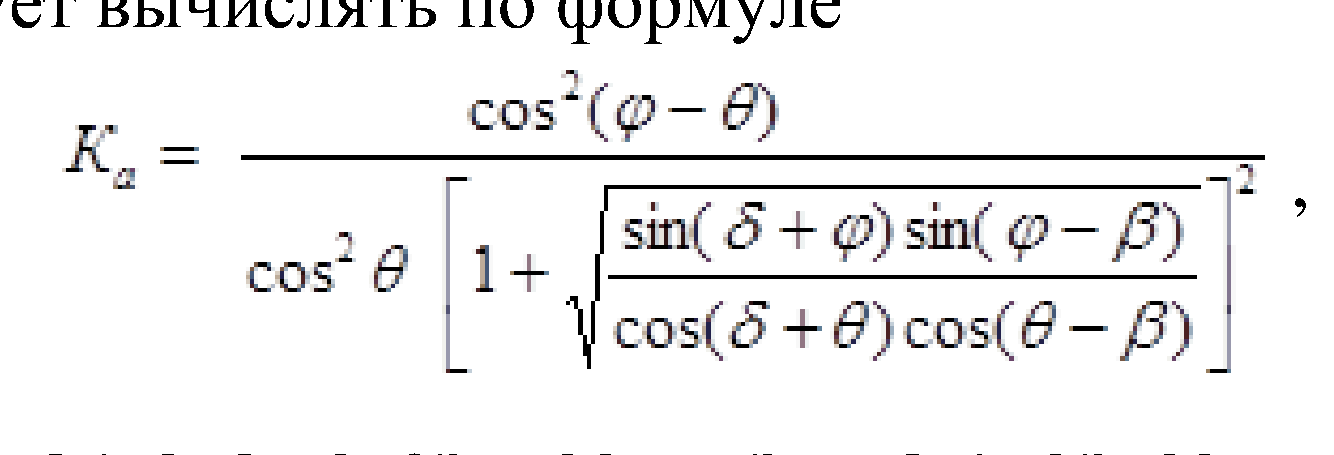

— (9.11) —


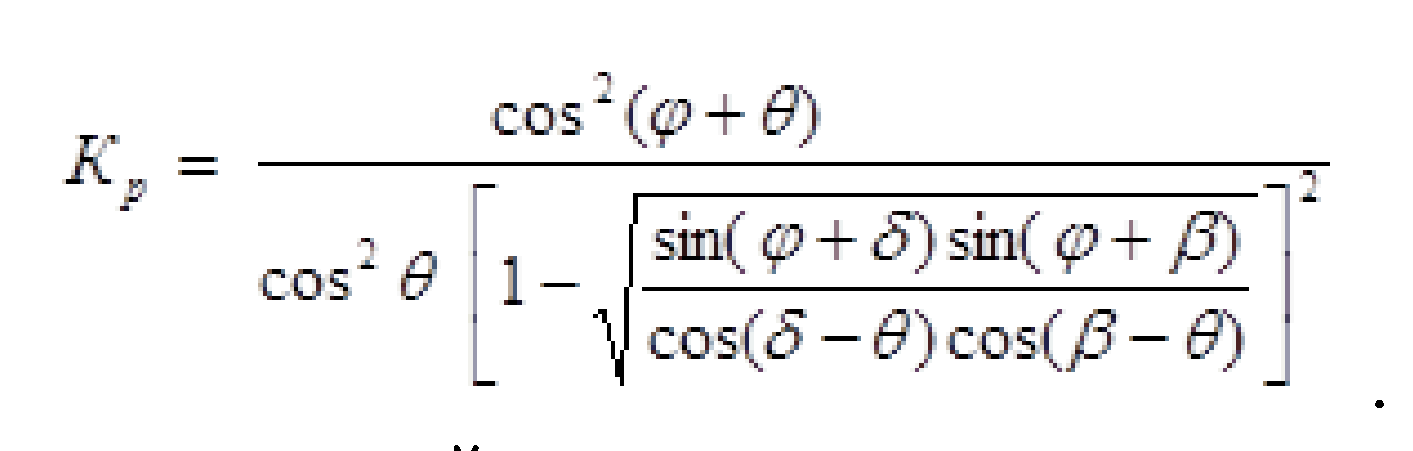

In [2]:
from IPython.display import Image, display

crops = {}
with pdfplumber.open(nb11.PDF) as doc:
    for number, (page_no, clause) in nb11.TARGETS.items():
        page = doc.pages[page_no - 1]
        rb = nb11.raster_bbox(page, number)
        im = next(i for i in page.images if abs(i["top"] - rb[1]) < 0.1)
        png = nb11.CROPS_DIR / f"nb11_{number.replace('.', '_')}.png"
        nb11.render_crop(page, rb).save(png)
        crops[number] = png
        print(f"({number}) p{page_no} (пункт {clause}): растр src={im['srcsize']} "
              f"bbox=({rb[0]:.0f},{rb[1]:.0f},{rb[2]:.0f},{rb[3]:.0f})")

for number, png in crops.items():
    print(f"— ({number}) —")
    display(Image(filename=str(png), width=440))

## 2. Обозначения из текстового слоя

«где …» для (9.7) (стр. 162) и δ — общее для обеих формул (стр. 161, формула (9.6)):

- β — угол наклона поверхности грунта к горизонту;
- θ — угол отклонения грани конструкции от вертикали;
- φ — угол внутреннего трения грунта;
- δ — угол трения грунта по материалу конструкции (по 9.16).

In [3]:
with pdfplumber.open(nb11.PDF) as doc:
    p161 = doc.pages[160].extract_text() or ""
    p162 = doc.pages[161].extract_text() or ""

print("(9.7) обозначения, стр. 162:")
for line in p162.splitlines():
    if "угол" in line or "где" in line:
        print("  ", line)
print()
print("δ (стр. 161, формула (9.6)):")
for line in p161.splitlines():
    if "9.16" in line or ("δ" in line and "трения" in line):
        print("  ", line)

(9.7) обозначения, стр. 162:
   где  – угол наклона поверхности грунта к горизонту,
    – угол отклонения грани конструкции от вертикали
    – угол внутреннего трения грунта.
   где K − коэффициент пассивного давления;

δ (стр. 161, формула (9.6)):
   где δ – угол трения грунта по материалу конструкции, определяемый в
   соответствии с 9.16.


## 3. OCR (pix2text) и каноничный LaTeX

Что вернул pix2text (сырой) и что заносим как проверенную формулу (clean + expression).

In [4]:
for number, png in crops.items():
    print(f"==== ({number}) ====")
    print("OCR  :", nb11.ocr_latex(png))
    print("CLEAN:", nb11.CLEAN_LATEX[number])
    print("expr :", nb11.EXPRESSION[number])
    print()

==== (9.7) ====


Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.


Could not find any ONNX files with standard file name decoder_model_merged.onnx, files found: [PosixPath('encoder_model.onnx'), PosixPath('decoder_model.onnx')]. Please make sure to pass a `file_name` and/or `subfolder` argument to `from_pretrained` when loading an ONNX file with non-standard file names.


  0%|          | 0/1 [00:00<?, ?it/s]

100%|██████████| 1/1 [00:03<00:00,  3.78s/it]

100%|██████████| 1/1 [00:03<00:00,  3.78s/it]

... (2 outputs left out)

  0%|          | 0/1 [00:00<?, ?it/s]

100%|██████████| 1/1 [00:03<00:00,  3.15s/it]

100%|██████████| 1/1 [00:03<00:00,  3.15s/it]

OCR  : K_{p} \,=\, \frac{\operatorname{c o s}^{2} ( \varphi+\theta)} {\operatorname{c o s}^{2} \theta\, \left[ 1-\sqrt{\frac{\operatorname{s i n} ( \varphi+\bar{\delta} ) \operatorname{s i n} ( \varphi+\bar{\beta} )} {\operatorname{c o s} ( \delta-\theta) \operatorname{c o s} ( \beta-\bar{\theta} )}} \, \right]^{2}}} \, \, \, .
CLEAN: K_p = \frac{\cos^2(\varphi + \theta)}{\cos^2 \theta \left[ 1 - \sqrt{\frac{\sin(\varphi + \delta)\sin(\varphi + \beta)}{\cos(\delta - \theta)\cos(\beta - \theta)}} \right]^2}
expr : cos(phi + theta)**2 / (cos(theta)**2 * (1 - sqrt(sin(phi + delta)*sin(phi + beta) / (cos(delta - theta)*cos(beta - theta))))**2)



## 4. Проверка: общий случай сводится к частному

При β=θ=δ=0 общий случай должен давать (9.8)/(9.12) = tg²(45° ∓ φ/2). Численная сверка.

In [5]:
for number, (page_no, clause) in nb11.TARGETS.items():
    sign = -1 if clause == 9.22 else 1
    print(f"({number}) → tg²(45° {'−' if sign < 0 else '+'} φ/2):")
    nb11.reduce_to_special(nb11.EXPRESSION[number], sign)
    print()

(9.7) → tg²(45° − φ/2):
  φ=0.3: общий=0.543781401260  частный=0.543781401260  |Δ|=1.1e-16  OK
  φ=0.6: общий=0.278247289082  частный=0.278247289082  |Δ|=0.0e+00  OK
  φ=1.0: общий=0.086088250372  частный=0.086088250372  |Δ|=4.2e-17  OK

(9.11) → tg²(45° + φ/2):
  φ=0.3: общий=1.838974260030  частный=1.838974260030  |Δ|=2.2e-16  OK
  φ=0.6: общий=3.593925401030  частный=3.593925401030  |Δ|=8.9e-16  OK
  φ=1.0: общий=11.615987032887  частный=11.615987032887  |Δ|=1.8e-15  OK



## 5. Выводы и реестр

- Обе формулы OCR распознаёт верно: греческий алфавит без кириллицы, поэтому pix2text
  здесь не калечит текст (в отличие от кириллических индексов, где он давал `h_зар→h_3arrom`).
- Сведение общего случая к частному (9.8)/(9.12) сходится с точностью ~1e-15 → формулы
  математически верны и согласованы с уже извлечёнными частными случаями.
- Итог — проверенный реестр (`formulas.toml`):

  - **(9.7)**, пункт 9.22: `K_a` — коэффициент активного давления (clean/expr выше);
  - **(9.11)**, пункт 9.23: `K_p` — коэффициент пассивного давления (clean/expr выше).

Символы: φ (угол внутреннего трения), β (наклон поверхности к горизонту), θ (отклонение
грани от вертикали), δ (трение по материалу конструкции, 9.16); K_a/K_p — безразмерные output.

**Открыто:** итоговая визуальная сверка PDF↔LaTeX — за человеком (договорено для пилота).
Артефакты низкого разрешения у (9.11): OCR вернул `\bar{δ}`/`\bar{β}`/`\bar{θ}` и
`\operatorname{cos}` — в каноничный LaTeX не попадают.